# Meteo Italia · Francesco
## Estrazione e controlli — progetto BSML

Questo notebook è autonomo: puoi caricare **solo questo file** in Google Colab oppure aprirlo con Jupyter.

**Stato consegna:** estrazione reale completata il 1 novembre 2026. Verificati 35.064 timestamp orari UTC, 18 colonne meteo, 288 risposte originali e 631.152 valori. Nessun valore mancante; nessun duplicato; nessun superamento delle soglie di controllo. Ogni valore del CSV è stato confrontato con la risposta originale. Grafici verificati visivamente.

Il notebook include i risultati già calcolati. La configurazione predefinita usa i JSON inclusi nel pacchetto, senza richiedere nuovi download. Per riprodurre tutto, estrai il pacchetto mantenendo le cartelle e apri questo notebook in Jupyter. Se carichi soltanto il notebook su Colab, imposta `OFFLINE = False` per riscaricare i dati. Per il trasferimento nel repository vedi il README nella cartella di Francesco.

**Attenzione metodologica:** il download seguente usa **rianalisi ERA5**, ricostruzioni a posteriori. Non sono osservazioni dirette di stazione e **non sono input validi per certificare un backtest day-ahead**. La sezione finale spiega la verifica forecast ancora necessaria.

Città: Milano, Torino, Bologna, Roma, Napoli e Palermo. Variabili: temperatura, umidità relativa e copertura nuvolosa. Nessuna modifica al repository ufficiale.

### 1 · Preparazione
Su Colab le librerie seguenti sono normalmente già disponibili. In locale usa `notebooks/francesco/requirements_weather.txt`. Non servono GPU, accesso a Google Drive o chiavi API per questa estrazione pubblica.


In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib
print('Librerie disponibili:', pd.__version__, np.__version__, matplotlib.__version__)


Librerie disponibili: 2.2.3 2.3.5 3.10.8


### 2 · Configurazione
Date iniziale e finale **incluse**, interpretate in UTC. Periodo iniziale: 2022–2025, da allineare in seguito con i dati elettrici di Marco.

Per una prova breve puoi cambiare le date in `2025-01-01` e `2025-01-07`; poi ripristina il periodo completo. Un'esecuzione breve esporta soltanto quell'intervallo. I download completati vengono riutilizzati nella stessa sessione/cartella.


In [2]:
START_DATE = '2022-01-01'
END_DATE = '2025-12-31'
OFFLINE = True  # Rilettura dei JSON originali inclusi; False per un nuovo download

cwd = Path.cwd()
if cwd.name == 'francesco' and cwd.parent.name == 'notebooks':
    ROOT = cwd.parent.parent
elif (cwd / 'notebooks/francesco/weather_pipeline.py').exists() or cwd.name == 'weather_francesco':
    ROOT = cwd
else:
    ROOT = cwd / 'weather_francesco'
ROOT.mkdir(parents=True, exist_ok=True)
print('Cartella di lavoro:', ROOT)
print('Periodo richiesto:', START_DATE, '—', END_DATE)


Cartella di lavoro: /workspace/scratch/90a686cf8c1d/weather_delivery
Periodo richiesto: 2022-01-01 — 2025-12-31


### 3 · Funzioni di estrazione e controllo
La cella contiene il codice completo per rendere il notebook autonomo; non occorre modificarla.

Si usa esplicitamente ERA5, evitando un cambio automatico di modello nel periodo. Le richieste sono mensili per ciascuna città. I JSON originali vengono conservati senza sovrascrittura, con metadati e checksum. Le coordinate richieste e quelle effettivamente restituite dall'API sono registrate.

I controlli interrompono l'elaborazione in presenza di duplicati, unità inattese o timestamp non validi. Le ore assenti vengono reintrodotte con NaN; nessuna interpolazione, sostituzione con zero o eliminazione automatica. Umidità e nuvolosità fuori da 0–100% e temperature fuori da −50–60 °C sono segnalate e conservate; la soglia termica è un filtro prudenziale per le sei città.


In [3]:
"""Open-Meteo ERA5 extraction. Reanalysis is for exploration, not day-ahead inputs."""
from __future__ import annotations

import argparse
import hashlib
import json
import time
import urllib.error
import urllib.parse
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

CITIES = {
    'milano': (45.4642, 9.1900),
    'torino': (45.0703, 7.6869),
    'bologna': (44.4949, 11.3426),
    'roma': (41.9028, 12.4964),
    'napoli': (40.8518, 14.2681),
    'palermo': (38.1157, 13.3615),
}
VARIABLES = {
    'temperature_2m': ('temp', 'c', '°C'),
    'relative_humidity_2m': ('humidity', 'pct', '%'),
    'cloud_cover': ('cloud_cover', 'pct', '%'),
}
ENDPOINT = 'https://archive-api.open-meteo.com/v1/archive'
MODEL = 'era5'


def utc_now():
    return datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ')


def hourly_index(start, end):
    """Inclusive UTC calendar dates: the end includes its entire final day."""
    a, b = pd.Timestamp(start, tz='UTC'), pd.Timestamp(end, tz='UTC')
    if a != a.normalize() or b != b.normalize() or b < a:
        raise ValueError('Use ordered date-only bounds YYYY-MM-DD.')
    return pd.date_range(a, b + pd.Timedelta(days=1), freq='h', inclusive='left', name='timestamp_utc')


def chunks(start, end):
    index = hourly_index(start, end)
    day = index[0]
    last = index[-1].normalize()
    while day <= last:
        stop = min(day + pd.offsets.MonthEnd(0), last)
        yield str(day.date()), str(stop.date())
        day = stop + pd.Timedelta(days=1)


def request_params(city, start, end):
    lat, lon = CITIES[city]
    return dict(latitude=lat, longitude=lon, start_date=start, end_date=end,
                hourly=','.join(VARIABLES), models=MODEL, timezone='UTC',
                temperature_unit='celsius', timeformat='iso8601')


def url_for(city, start, end):
    return ENDPOINT + '?' + urllib.parse.urlencode(request_params(city, start, end))


def load_payload(content):
    payload = json.loads(content)
    if not isinstance(payload, dict) or payload.get('error') or 'hourly' not in payload:
        raise ValueError('Invalid API response: ' + str(payload)[:240])
    return payload


def parse_hourly(payload, city, start, end):
    """Reject duplicates/units/time errors; retain NaN and anomalies unchanged."""
    if payload.get('utc_offset_seconds') != 0:
        raise ValueError('Response is not UTC.')
    hourly, units = payload['hourly'], payload.get('hourly_units', {})
    idx = pd.DatetimeIndex(pd.to_datetime(hourly['time'], utc=True), name='timestamp_utc')
    if idx.hasnans or idx.has_duplicates:
        raise ValueError(f'{city}: invalid or duplicate timestamps; inspect raw response.')
    expected = hourly_index(start, end)
    if not idx.isin(expected).all():
        raise ValueError(f'{city}: off-hour or out-of-range timestamps.')
    data = {}
    for key, (prefix, suffix, unit) in VARIABLES.items():
        if units.get(key) != unit:
            raise ValueError(f'{city}/{key}: unexpected or absent unit {units.get(key)!r}.')
        values = hourly.get(key)
        if not isinstance(values, list) or len(values) != len(idx):
            raise ValueError(f'{city}/{key}: absent array or length mismatch.')
        numeric = pd.to_numeric(pd.Series(values), errors='raise').to_numpy(dtype=float)
        data[f'{prefix}_{city}_{suffix}'] = numeric
    # No aggregation or interpolation: ERA5 hourly values are used as returned.
    return pd.DataFrame(data, index=idx).sort_index()


def obtain_raw(root, city, start, end, offline=False):
    """Cache original bytes using exclusive create. Existing files never overwritten."""
    params = request_params(city, start, end)
    digest = hashlib.sha256(json.dumps(params, sort_keys=True).encode()).hexdigest()[:12]
    directory = Path(root) / 'data/raw/weather_reanalysis'
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / f'{city}_{start}_{end}_{digest}.json'
    meta_path = path.with_suffix('.metadata.json')
    cached = path.exists()
    if cached:
        content = path.read_bytes()
    else:
        if offline:
            raise FileNotFoundError(f'Raw response absent: {path.name}')
        request = urllib.request.Request(url_for(city, start, end),
                                        headers={'User-Agent': 'BSML-weather-student-project/1.0'})
        for attempt in range(4):
            try:
                with urllib.request.urlopen(request, timeout=60) as response:
                    content = response.read()
                load_payload(content)
                break
            except urllib.error.HTTPError as exc:
                detail = exc.read().decode('utf-8', errors='replace')[:400]
                if exc.code not in (429, 500, 502, 503, 504) or attempt == 3:
                    raise RuntimeError(f'Open-Meteo HTTP {exc.code}: {detail}') from exc
                time.sleep(2 ** attempt)
            except (urllib.error.URLError, TimeoutError):
                if attempt == 3:
                    raise
                time.sleep(2 ** attempt)
        with path.open('xb') as handle:
            handle.write(content)
        meta = dict(url=url_for(city, start, end), params=params, retrieved_at_utc=utc_now(),
                    sha256=hashlib.sha256(content).hexdigest(), source_kind='reanalysis', model=MODEL)
        with meta_path.open('x', encoding='utf-8') as handle:
            json.dump(meta, handle, indent=2)
        time.sleep(0.6)
    payload = load_payload(content)
    checksum = hashlib.sha256(content).hexdigest()
    if meta_path.exists():
        meta = json.loads(meta_path.read_text(encoding='utf-8'))
        if meta.get('sha256') != checksum or meta.get('params') != params:
            raise ValueError(f'Raw integrity/request mismatch: {path}')
    else:
        meta = dict(retrieved_at_utc=None)
    provenance = dict(city=city, start_date=start, end_date=end,
                      raw_file=path.relative_to(root).as_posix(), sha256=checksum,
                      retrieved_at_utc=meta.get('retrieved_at_utc'), reused_cache=cached,
                      requested_latitude=CITIES[city][0], requested_longitude=CITIES[city][1],
                      returned_latitude=payload.get('latitude'), returned_longitude=payload.get('longitude'),
                      returned_elevation=payload.get('elevation'), model=MODEL, source_kind='reanalysis',
                      url=url_for(city, start, end))
    return payload, provenance


def quality_tables(frame, absent_by_city):
    summary, gaps, anomalies = [], [], []
    for col in frame:
        missing = frame[col].isna()
        city = next(city for city in CITIES if f'_{city}_' in col)
        absent = absent_by_city[city]
        summary.append(dict(dataset='weather_clean_reanalysis', column=col,
                            missing_count=int(missing.sum()), missing_pct=round(100 * missing.mean(), 6),
                            absent_hour_count=int(absent.sum()),
                            missing_cell_existing_hour_count=int((missing & ~absent).sum())))
        for kind, mask in [('absent_hour', missing & absent), ('missing_cell', missing & ~absent)]:
            positions = np.flatnonzero(mask.to_numpy())
            for group in np.split(positions, np.where(np.diff(positions) != 1)[0] + 1):
                if len(group):
                    gaps.append(dict(column=col, start_utc=frame.index[group[0]], end_utc=frame.index[group[-1]],
                                     hours=len(group), kind=kind, cause='not supplied by API; cause unknown'))
        v = frame[col]
        bounds = (-50, 60) if col.startswith('temp_') else (0, 100)
        bad = v.notna() & ((v < bounds[0]) | (v > bounds[1]) | ~np.isfinite(v))
        for timestamp, value in v[bad].items():
            anomalies.append(dict(timestamp_utc=timestamp, column=col, value=value,
                                  rule=f'outside [{bounds[0]}, {bounds[1]}] or non-finite',
                                  action='flagged; original value retained'))
    return (pd.DataFrame(summary),
            pd.DataFrame(gaps, columns=['column', 'start_utc', 'end_utc', 'hours', 'kind', 'cause']),
            pd.DataFrame(anomalies, columns=['timestamp_utc', 'column', 'value', 'rule', 'action']))


def save_csv(frame, path, index=False):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=index, na_rep='', date_format='%Y-%m-%dT%H:%M:%SZ')


def temperature_plots(frame, directory):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    columns = [f'temp_{city}_c' for city in CITIES]
    # Aggregations used only in plots; no values are filled in the clean dataset.
    daily = frame[columns].resample('D').mean()
    fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
    for ax, city, col in zip(axes.flat, CITIES, columns):
        ax.plot(daily.index, daily[col], lw=0.7)
        ax.set(title=city.capitalize(), ylabel='Temperature (°C)')
        ax.grid(alpha=0.2)
    fig.suptitle('ERA5 reanalysis — daily means of available hourly temperatures')
    fig.tight_layout()
    fig.savefig(directory / 'temperature_daily.png', dpi=150)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(11, 5))
    month = frame[columns].groupby(frame.index.month).mean()
    for city, col in zip(CITIES, columns):
        ax.plot(month.index, month[col], marker='o', label=city.capitalize())
    ax.set(xlabel='Month (UTC)', ylabel='Temperature (°C)',
           title='ERA5 reanalysis — monthly means of available hours', xticks=range(1, 13))
    ax.legend(ncol=3)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(directory / 'temperature_monthly.png', dpi=150)
    plt.close(fig)


def run(root, start='2022-01-01', end='2025-12-31', offline=False):
    root = Path(root).resolve()
    expected = hourly_index(start, end)
    reports = root / 'reports/weather'
    reports.mkdir(parents=True, exist_ok=True)
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    log_path = reports / f'extraction_{run_id}.json'
    status = dict(start_date=start, end_date=end, started_at_utc=utc_now(), status='running',
                  source_kind='reanalysis', model=MODEL, day_ahead_eligible=False, requests=[])
    frames, absent_by_city = [], {}
    try:
        for city in CITIES:
            parts = []
            for a, b in chunks(start, end):
                print(f'{city}: {a} → {b}', flush=True)
                payload, provenance = obtain_raw(root, city, a, b, offline=offline)
                try:
                    part = parse_hourly(payload, city, a, b)
                except Exception:
                    status['failed_raw_file'] = provenance['raw_file']
                    raise
                status['requests'].append(provenance)
                parts.append(part)
            frame = pd.concat(parts).sort_index()
            if frame.index.has_duplicates:
                raise ValueError(f'{city}: duplicates across chunks; no automatic removal.')
            absent_by_city[city] = pd.Series(~expected.isin(frame.index), index=expected)
            frames.append(frame.reindex(expected))
        clean = pd.concat(frames, axis=1)
        if clean.index.has_duplicates or len(clean.columns) != 18 or len(clean) != len(expected):
            raise ValueError('Final structural check failed.')
        missing, gaps, anomalies = quality_tables(clean, absent_by_city)
        # Publish only after all six cities have been extracted and validated.
        save_csv(clean, root / 'data/processed/weather_clean.csv', index=True)
        save_csv(missing, reports / 'missing_values_report.csv')
        save_csv(gaps, reports / 'missing_intervals.csv')
        save_csv(anomalies, reports / 'anomalies.csv')
        save_csv(pd.DataFrame(status['requests']), reports / 'provenance.csv')
        dictionary = []
        for city in CITIES:
            for api, (prefix, suffix, unit) in VARIABLES.items():
                dictionary.append(dict(column=f'{prefix}_{city}_{suffix}', city=city,
                                       api_variable=api, unit=unit, model=MODEL,
                                       source_kind='reanalysis', day_ahead_eligible=False))
        save_csv(pd.DataFrame(dictionary), reports / 'data_dictionary.csv')
        temperature_plots(clean, reports)
        status.update(status='complete_reanalysis_only', rows=len(clean),
                      total_missing_cells=int(clean.isna().sum().sum()), flagged_values=len(anomalies),
                      finished_at_utc=utc_now())
        (reports / 'weather_clean.metadata.json').write_text(json.dumps(status, indent=2), encoding='utf-8')
        print(f'Created {len(clean):,} hourly rows and 18 weather columns. REANALYSIS ONLY.')
        return clean, missing, gaps, anomalies
    except Exception as exc:
        status.update(status='failed', error=f'{type(exc).__name__}: {exc}', finished_at_utc=utc_now())
        raise
    finally:
        log_path.write_text(json.dumps(status, indent=2), encoding='utf-8')


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--root', type=Path, default=Path(__file__).resolve().parents[2])
    parser.add_argument('--start', default='2022-01-01')
    parser.add_argument('--end', default='2025-12-31')
    parser.add_argument('--offline', action='store_true', help='Use existing raw JSON only.')
    args = parser.parse_args()
    run(args.root, args.start, args.end, args.offline)



### 4 · Estrazione o ricostruzione dei dati reali
Questa cella ricostruisce i dati dai 288 JSON originali se `OFFLINE = True`; con `OFFLINE = False` riutilizza i JSON esistenti e scarica quelli mancanti. Se l'API rifiuta la richiesta, il notebook mostra l'errore e registra il tentativo; **non crea un CSV sostitutivo con dati inventati**. Per riprendere un download interrotto nella stessa cartella, riesegui questa cella.


In [4]:
result = None
try:
    result = run(ROOT, START_DATE, END_DATE, offline=OFFLINE)
except Exception as exc:
    print('ESTRAZIONE NON COMPLETATA:', type(exc).__name__, str(exc))
    print('I risultati di eventuali esecuzioni precedenti non certificano questo tentativo.')
    print('Su Colab: controlla la connessione e conserva questo messaggio per la diagnosi.')
    print('Il registro del tentativo si trova in reports/weather/.')


milano: 2022-01-01 → 2022-01-31
milano: 2022-02-01 → 2022-02-28
milano: 2022-03-01 → 2022-03-31
milano: 2022-04-01 → 2022-04-30
milano: 2022-05-01 → 2022-05-31
milano: 2022-06-01 → 2022-06-30
milano: 2022-07-01 → 2022-07-31
milano: 2022-08-01 → 2022-08-31
milano: 2022-09-01 → 2022-09-30
milano: 2022-10-01 → 2022-10-31
milano: 2022-11-01 → 2022-11-30
milano: 2022-12-01 → 2022-12-31
milano: 2023-01-01 → 2023-01-31
milano: 2023-02-01 → 2023-02-28
milano: 2023-03-01 → 2023-03-31
milano: 2023-04-01 → 2023-04-30
milano: 2023-05-01 → 2023-05-31
milano: 2023-06-01 → 2023-06-30
milano: 2023-07-01 → 2023-07-31
milano: 2023-08-01 → 2023-08-31
milano: 2023-09-01 → 2023-09-30
milano: 2023-10-01 → 2023-10-31
milano: 2023-11-01 → 2023-11-30
milano: 2023-12-01 → 2023-12-31
milano: 2024-01-01 → 2024-01-31
milano: 2024-02-01 → 2024-02-29
milano: 2024-03-01 → 2024-03-31
milano: 2024-04-01 → 2024-04-30
milano: 2024-05-01 → 2024-05-31
milano: 2024-06-01 → 2024-06-30
milano: 2024-07-01 → 2024-07-31
milano: 

### 5 · Controllo della struttura e report NaN
Il CSV finale ha una colonna chiave `timestamp_utc` e 18 colonne meteo. Nel periodo completo sono attese **35.064 righe** (compreso il 29 febbraio 2024). Le giornate di cambio dell'ora restano regolari in UTC.

Nel report distinguiamo le **ore completamente assenti nella risposta della città** dalle **celle nulle in ore presenti**. Gli intervalli consecutivi sono riportati separatamente. Le cause non note non vengono inventate.


In [5]:
if result is not None:
    clean, missing, gaps, anomalies = result
    print('Dimensioni:', len(clean), 'ore ×', len(clean.columns), 'variabili meteo')
    print('Prime righe:')
    print(clean.head().to_string())
    print('\nReport mancanti:')
    print(missing.to_string(index=False))
    print('\nIntervalli mancanti:', len(gaps), '| Valori segnalati:', len(anomalies))
    print(gaps.head(20).to_string(index=False))
    print(anomalies.head(20).to_string(index=False))
else:
    print('Report non disponibile: prima completare il download dei dati reali.')


Dimensioni: 35064 ore × 18 variabili meteo
Prime righe:
                           temp_milano_c  humidity_milano_pct  cloud_cover_milano_pct  temp_torino_c  humidity_torino_pct  cloud_cover_torino_pct  temp_bologna_c  humidity_bologna_pct  cloud_cover_bologna_pct  temp_roma_c  humidity_roma_pct  cloud_cover_roma_pct  temp_napoli_c  humidity_napoli_pct  cloud_cover_napoli_pct  temp_palermo_c  humidity_palermo_pct  cloud_cover_palermo_pct
timestamp_utc                                                                                                                                                                                                                                                                                                                                                                                    
2022-01-01 00:00:00+00:00            4.1                 93.0                    32.0            5.1                 83.0                    57.0             5.1           

### 6 · Grafici delle temperature
Due figure: andamento giornaliero per città e profilo medio mensile. Le medie impiegano le ore disponibili esclusivamente a fini grafici. Il CSV rimane orario, con i suoi NaN; non si corregge nulla sulla base del grafico. Anche i raggruppamenti dei grafici sono in UTC.


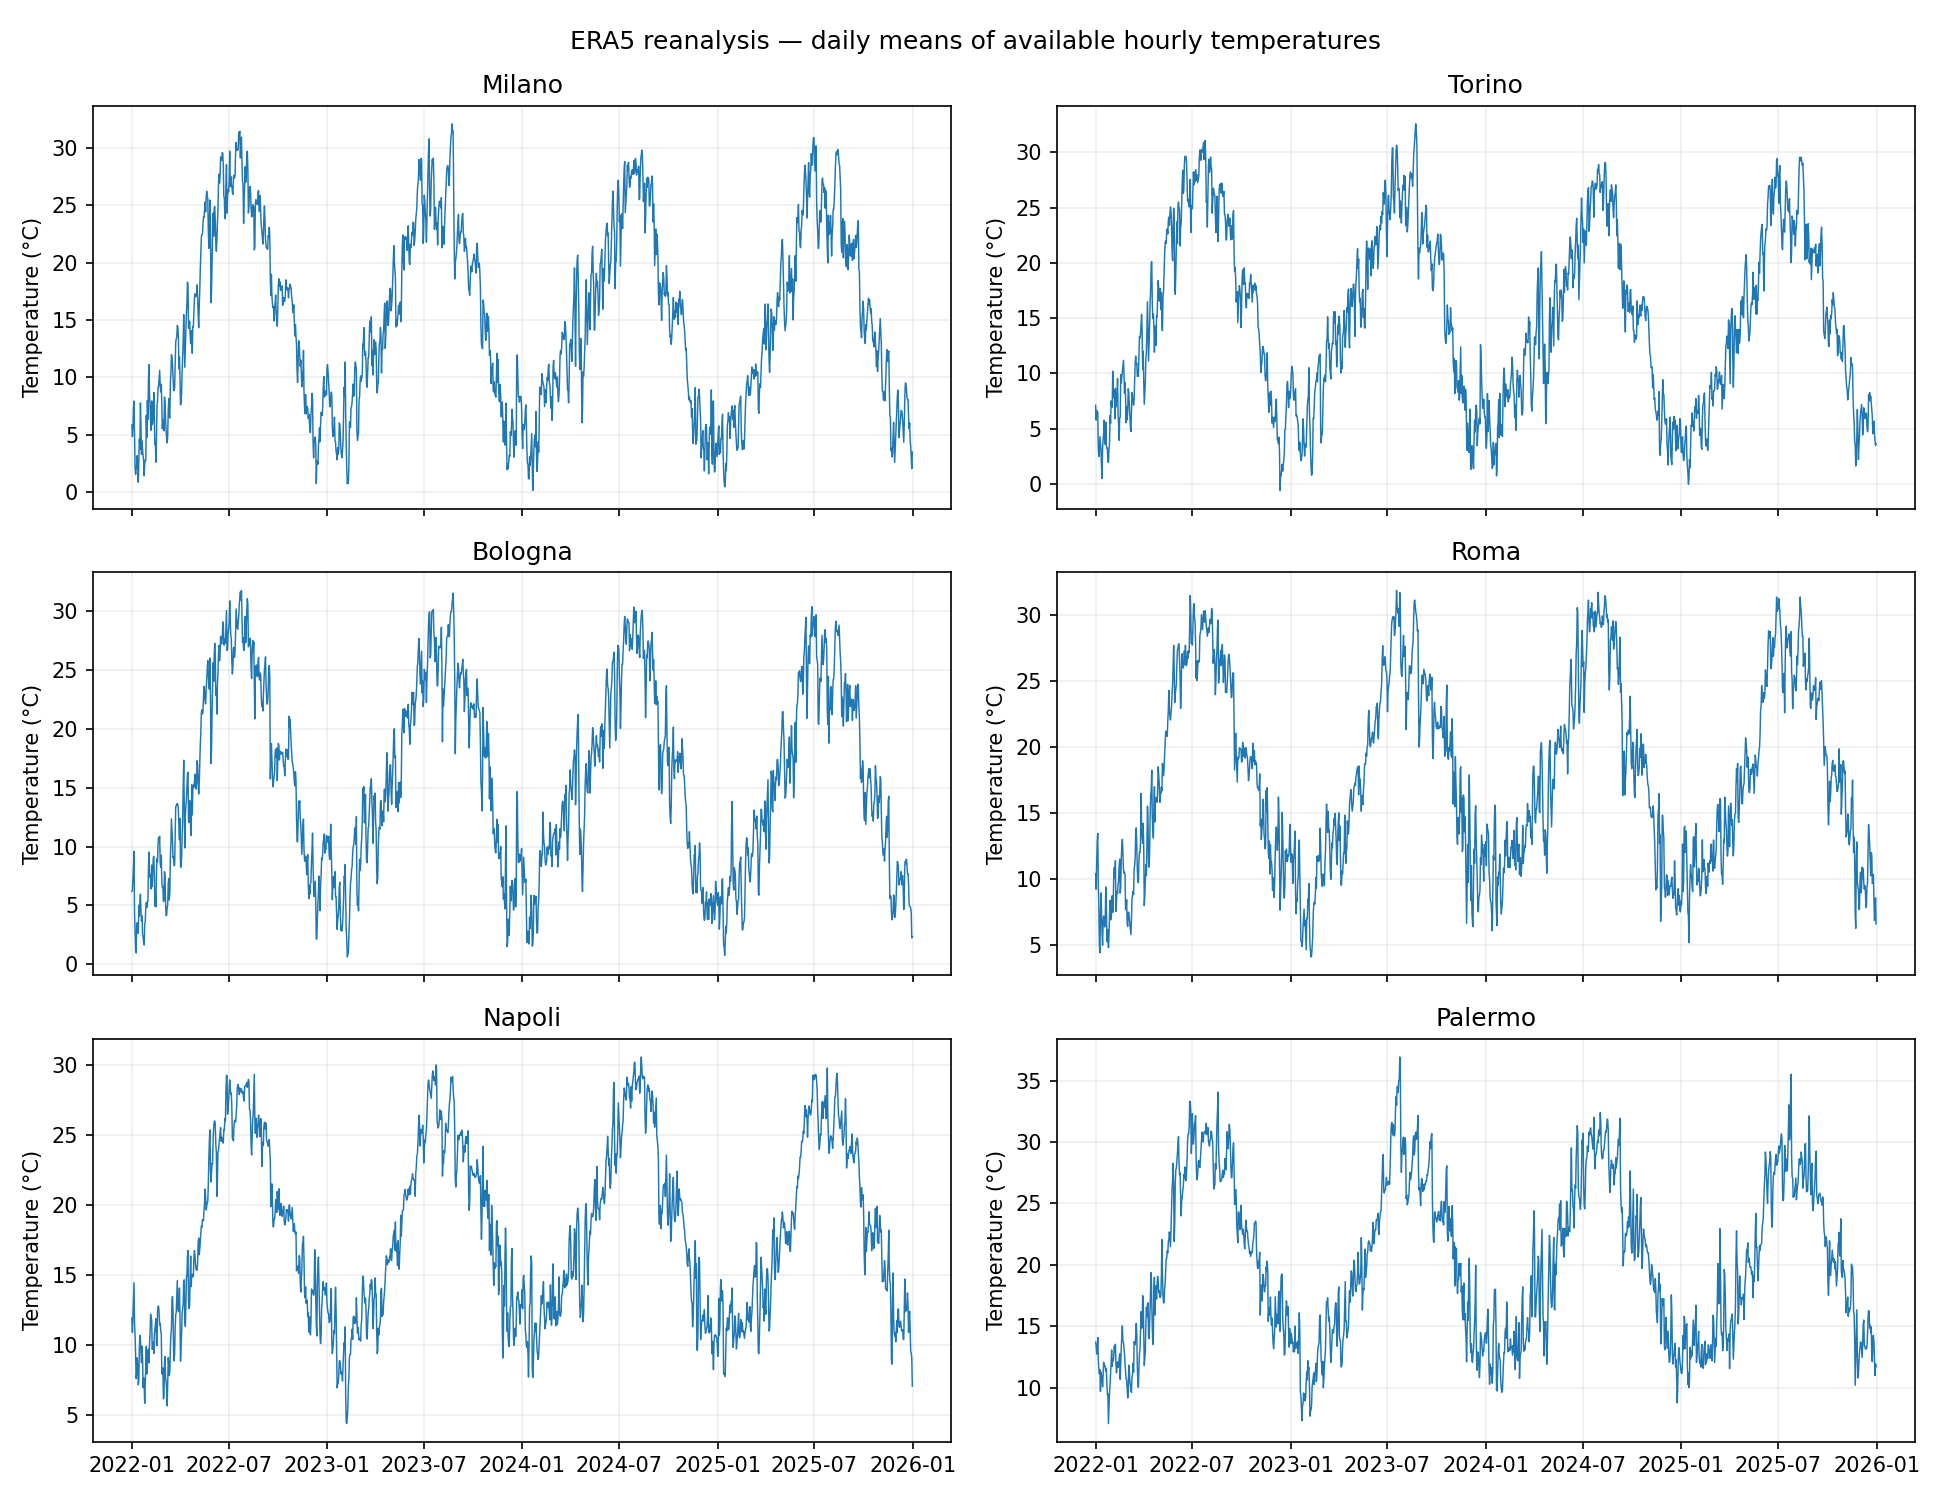

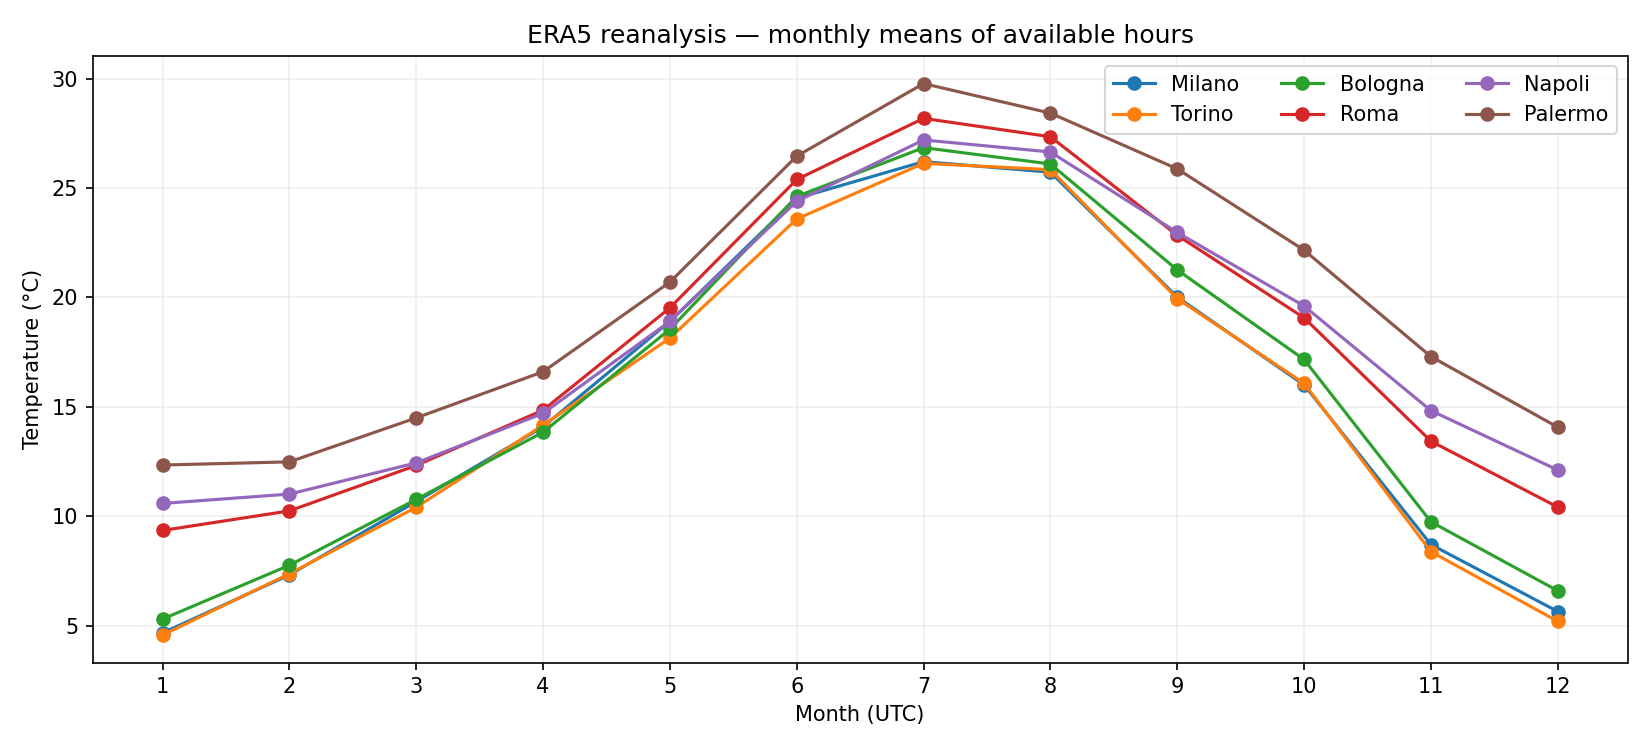

In [6]:
if result is not None:
    from IPython.display import display, Image
    for filename in ['temperature_daily.png', 'temperature_monthly.png']:
        display(Image(filename=str(ROOT / 'reports/weather' / filename)))
else:
    print('Nessun grafico reale disponibile: download non completato.')


### 7 · Esporta i risultati
La cella crea `weather_outputs.zip` contenente risposte originali, CSV, metadati, report e grafici. Su Colab puoi scaricarlo dal pannello File oppure impostare `DOWNLOAD_TO_COMPUTER = True` ed eseguire la cella. **Scarica i risultati prima che la sessione Colab termini**, altrimenti i file temporanei possono andare persi.

Non trasferire il CSV nel modello day-ahead senza conservarne la qualifica di rianalisi e risolvere la parte forecast.


In [ ]:
DOWNLOAD_TO_COMPUTER = False
if result is not None:
    import zipfile
    archive = ROOT.parent / 'weather_outputs.zip'
    with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for folder in ['data/raw', 'data/processed', 'reports/weather']:
            for path in sorted((ROOT / folder).rglob('*')):
                if path.is_file():
                    z.write(path, path.relative_to(ROOT))
    print('File pronto:', archive)
    if DOWNLOAD_TO_COMPUTER:
        from google.colab import files
        files.download(str(archive))
else:
    print('Esportazione non eseguita: il download reale non è completo.')


### 8 · Verifica forecast e punti aperti

# Previsioni meteo archiviate: verifica preliminare

**Esito: il dataset day-ahead finale non è ancora pronto.** L'estrazione esplorativa ERA5 2022–2025 è stata completata e verificata; non si può certificare una copertura forecast omogenea dell'intero periodo con le sole informazioni finora verificate. Verifica documentale: 1 novembre 2026. Copertura effettiva delle API forecast non ancora verificata. Il download Historical Weather è invece riuscito tramite Colab; i suoi dati sono allegati e verificati.

| Prodotto Open-Meteo | Natura | Conseguenza per il progetto |
| --- | --- | --- |
| Historical Weather, ERA5 | Rianalisi a posteriori | Adatta a esplorazione; non prova la disponibilità al cutoff day-ahead |
| Historical Forecast | Serie che concatena le prime ore di run successivi, con storia variabile per modello | La denominazione «forecast» non basta a ricostruire una previsione disponibile il giorno prima |
| Previous Runs | Serie a scadenza fissa di 1–7 giorni; generalmente da gennaio 2024, con eccezioni | Utile da approfondire; non è automaticamente una previsione unica per tutte le ore del giorno successivo |
| Single Runs | Run distinti per inizializzazione | Struttura più vicina alla necessità del progetto, da verificare per periodo e natura dell'archivio |

La documentazione delle Single Runs dichiara ECMWF IFS dal **14 marzo 2024**, ma specifica **IFS Cycle 49R1 hindcasts** per parte dell'archivio. Gli altri modelli sono indicati dal **2 aprile 2026**, fuori dall'intervallo 2022–2025. La presenza di hindcast richiede una verifica ulteriore: non va assimilata automaticamente al forecast operativo davvero pubblicato in quella data. L'inizializzazione del run non coincide inoltre con il momento di disponibilità pubblica.

La documentazione Previous Runs segnala storia più lunga per la temperatura GFS (da marzo 2021) e per alcuni modelli JMA (dal 2018). Questo **non verifica** la copertura di tutte e tre le variabili nelle sei città per l'intero intervallo: vanno interrogate e controllate singolarmente.

## Decisioni da concordare con il gruppo prima della costruzione forecast finale

1. **Cutoff della previsione elettrica:** quale ora del giorno precedente, e in quale fuso? Non assumere mezzanotte o un'ora non indicata.
2. **Autenticità dell'archivio:** run operativi originari oppure hindcast ricostruiti? Per un backtest rigoroso verificare la fonte con Open-Meteo se la documentazione non basta.
3. **Disponibilità:** scegliere solo run effettivamente pubblicati entro il cutoff. Un semplice `run_time_utc <= cutoff` è insufficiente.
4. **Copertura:** verificare tutte le variabili, i modelli e le sei città. Se il periodo completo non è disponibile, documentare i vuoti o concordare un intervallo minore; mai riempire con ERA5.

Queste verifiche restano necessarie anche se un'API risponde senza errori.

## Schema previsto, da finalizzare

File distinto: `weather_forecast_clean.csv`, in formato lungo.

| Colonna | Significato |
| --- | --- |
| `issue_time_utc` | Emissione del forecast, con definizione documentata |
| `run_time_utc` | Inizializzazione del modello |
| `available_time_utc` | Prima disponibilità pubblica, oppure stima esplicita e giustificata |
| `target_time_utc` | Ora futura cui si riferisce il valore |
| `city` | Città |
| `model` | Modello, versione quando disponibile |
| `source_kind` | Forecast operativo oppure hindcast, tenuti distinti |
| `temp_c`, `humidity_pct`, `cloud_cover_pct` | Variabili previste |

Non inventare `issue_time_utc` sottraendo 24 ore a `target_time_utc`. Non confondere inizializzazione, emissione e disponibilità. Definire la chiave sulla base di modello/run/città/target; selezionare il run con una regola unica documentata. Validare il giorno target in `Europe/Rome`, incluse le giornate di 23/25 ore.

## Fonti ufficiali

- https://open-meteo.com/en/docs/historical-weather-api
- https://open-meteo.com/en/docs/historical-forecast-api
- https://open-meteo.com/en/docs/previous-runs-api
- https://open-meteo.com/en/docs/single-runs-api
- https://open-meteo.com/en/docs/model-updates

La scelta di non certificare ancora il backtest è una valutazione metodologica basata su queste limitazioni, non una dichiarazione che qualsiasi archivio operativo alternativo sia indisponibile.


### 9 · Consegna e fonti

Output esplorativo: `weather_clean.csv`, questo notebook, report mancanti e grafici. File da mantenere separati dai forecast. Radiazione solare esclusa perché facoltativa; durata del giorno di competenza calendario.

Quando il download riesce, rieseguire i controlli e verificare i valori reali: i test offline del pacchetto controllano il codice con dati sintetici e non certificano il contenuto di Open-Meteo.

Fonti ufficiali consultate il 1 novembre 2026:
- [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)
- [Historical Forecast API](https://open-meteo.com/en/docs/historical-forecast-api)
- [Previous Runs API](https://open-meteo.com/en/docs/previous-runs-api)
- [Single Runs API](https://open-meteo.com/en/docs/single-runs-api)
- [Model Updates](https://open-meteo.com/en/docs/model-updates)
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)

Attribuzione dati prevista: Open-Meteo, rianalisi ERA5 (ECMWF/Copernicus). Verificare [licenza](https://open-meteo.com/en/licence) e [termini](https://open-meteo.com/en/terms) prima della diffusione. Nessuna chiave o credenziale nel notebook.


### 10 · Risultati verificati sui dati reali

35.064 ore UTC; 18 colonne meteo; 0 valori mancanti; 0 duplicati; 0 superamenti delle soglie. Verificati i checksum di 288 risposte originali e confrontate esattamente tutte le 631.152 celle meteo del CSV con quelle risposte. La ricostruzione offline conserva lo stesso hash del CSV caricato da Francesco. Questi controlli certificano la corrispondenza con il prodotto ricevuto, non la precisione rispetto a stazioni meteo indipendenti.

| Città | Temperatura media (°C) | Minimo orario (°C) | Massimo orario (°C) |
| --- | --- | --- | --- |
| Milano | 15.25 | -4.0 | 38.8 |
| Torino | 15.03 | -4.2 | 39.5 |
| Bologna | 15.76 | -4.3 | 38.8 |
| Roma | 17.79 | -1.0 | 39.8 |
| Napoli | 17.99 | 0.9 | 35.6 |
| Palermo | 20.10 | 2.8 | 43.2 |

I grafici mostrano quattro cicli stagionali senza discontinuità macroscopiche evidenti. Le coordinate restituite sono punti di griglia: consultare `provenance.csv`. Nessun riempimento, interpolazione o sostituzione con zero. La verifica dettagliata è in `reports/weather/verification_report.md` e lo script indipendente in `notebooks/francesco/verify_weather.py`.

**Questa consegna completa la parte esplorativa ERA5. La componente forecast per il backtest finale richiede le verifiche della sezione 8.**
